# Why Rebuild a Walking Robot Duck in Modelica?

MuJoCo trains the [Pollen Robotics and Hugging Face Microduck](https://www.youtube.com/watch?v=Nt6d62vN7CU) walking policy fast, using a Python callback before every `mj_step` with a fixed supply voltage per episode, 14 extra 3D hinges to mimic 2° of gear play, and a contact law compiled into the C solver. Rebuilding the robot in Modelica puts the 3D multibody tree, the 1D drivetrains, the 2S lithium-ion battery pack (`useBattery = true`), the two-node servo thermal network (`useThermal = true`) and the sole contact equations (`PointContact`) in one declarative plant, exported as `DuckPlant.fmu`.

- **Article:** [Why Rebuild a Walking Robot Duck in Modelica?](https://nouseng.co/libraries/atelier/microduck/why-modelica/)
- **Modelica library (`MicroDuck` & `MicroDuckTest`):** [`nouseng/libraries/RoboticsAtelier/MicroDuck`](https://github.com/nouseng/libraries/tree/main/RoboticsAtelier/MicroDuck)
- **MuJoCo robot model & meshes (`mujoco/model/`):** [`pollen-robotics/microduck_rl`](https://github.com/pollen-robotics/microduck_rl) (Apache-2.0)
- **Trained walking policy (`mujoco/velstand.onnx`):** [`pollen-robotics/microduck-policies`](https://huggingface.co/pollen-robotics/microduck-policies) (Apache-2.0)
- **Identified XL330 servo model:** [`Rhoban/bam`](https://github.com/Rhoban/bam) (Apache-2.0)
- **Setup and files:** [README.md](README.md)

In [1]:
from common import *  # FMU and MuJoCo helpers, plot style

## 1. Standing drop check (`positionGain = 800`)

Dropped from 2.8 mm onto its soles with the servos holding the home pose at `positionGain = 800`, both simulators settle at half of the 7.2 N robot weight per sole and agree within 0.2 mm on trunk height.

settled sole loads (N): MicroDuck (3.62, 3.61) vs MuJoCo (3.62, 3.61)
settled trunk height (mm): 116.32 vs 116.13


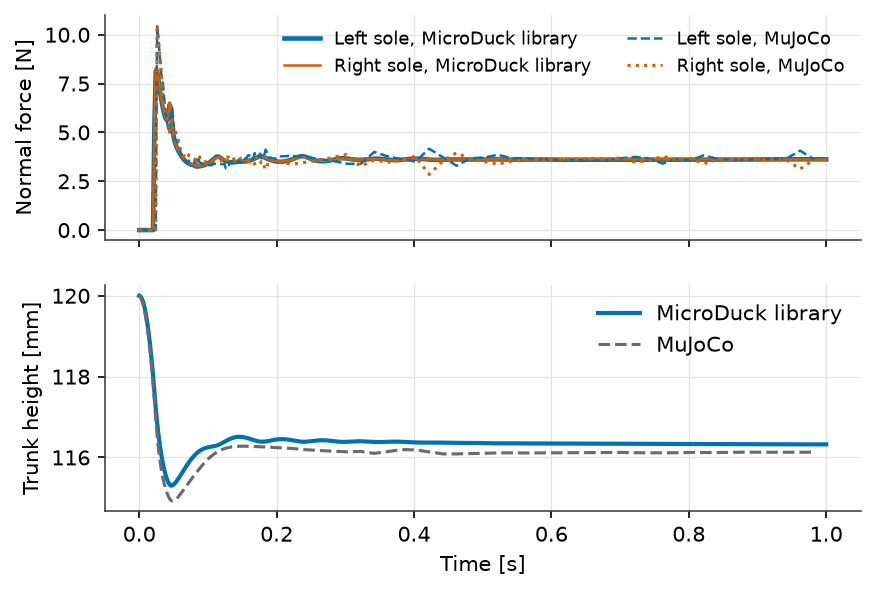

In [2]:
sd = stand_fmu(800, 1.0)
sm = stand_mujoco(800, 1.0)
print(f"settled sole loads (N): MicroDuck ({sd['leftLoad'].iloc[-1]:.2f}, {sd['rightLoad'].iloc[-1]:.2f}) vs MuJoCo ({sm['leftLoad'].iloc[-1]:.2f}, {sm['rightLoad'].iloc[-1]:.2f})")
print(f"settled trunk height (mm): {1e3 * sd['trunkHeight'].iloc[-1]:.2f} vs {1e3 * sm['trunkHeight'].iloc[-1]:.2f}")

fig, (a1, a2) = plt.subplots(2, 1, figsize=(6.5, 4.3), sharex=True)
a1.plot(sd["time"], sd["leftLoad"], color=BLUE, lw=2.2, label="Left sole, MicroDuck library")
a1.plot(sd["time"], sd["rightLoad"], color=ORANGE, lw=1.2, label="Right sole, MicroDuck library")
a1.plot(sm["time"], sm["leftLoad"], color=BLUE, ls="--", lw=1.2, label="Left sole, MuJoCo")
a1.plot(sm["time"], sm["rightLoad"], color=ORANGE, ls=":", lw=1.5, label="Right sole, MuJoCo")
a1.set_ylabel("Normal force [N]"); a1.legend(loc="upper right", ncol=2, fontsize=8.5)
a2.plot(sd["time"], 1e3 * sd["trunkHeight"], color=BLUE, label="MicroDuck library")
a2.plot(sm["time"], 1e3 * sm["trunkHeight"], color=GREY, ls="--", lw=1.5, label="MuJoCo")
a2.set_ylabel("Trunk height [mm]"); a2.set_xlabel("Time [s]"); a2.legend(loc="upper right")
plt.show()

## 2. Closed-loop walk (`0.3 m/s` command)

Same 50 Hz ONNX policy, same 0.3 m/s forward command, two simulators.

In [3]:
duck = walk_fmu()
mj = walk_mujoco(speed_command=0.3)
print(f"MicroDuck library {speed(duck):.3f} m/s, MuJoCo {speed(mj):.3f} m/s over the last 4 s")
print(f"distance after 6 s: {duck['distance'].iloc[-1]:.3f} m against {mj['distance'].iloc[-1]:.3f} m")
print(f"mean trunk height: {1e3 * duck['trunkHeight'].mean():.1f} mm against {1e3 * mj['trunkHeight'].mean():.1f} mm")

MicroDuck library 0.137 m/s, MuJoCo 0.132 m/s over the last 4 s
distance after 6 s: 0.798 m against 0.799 m
mean trunk height: 118.2 mm against 118.1 mm


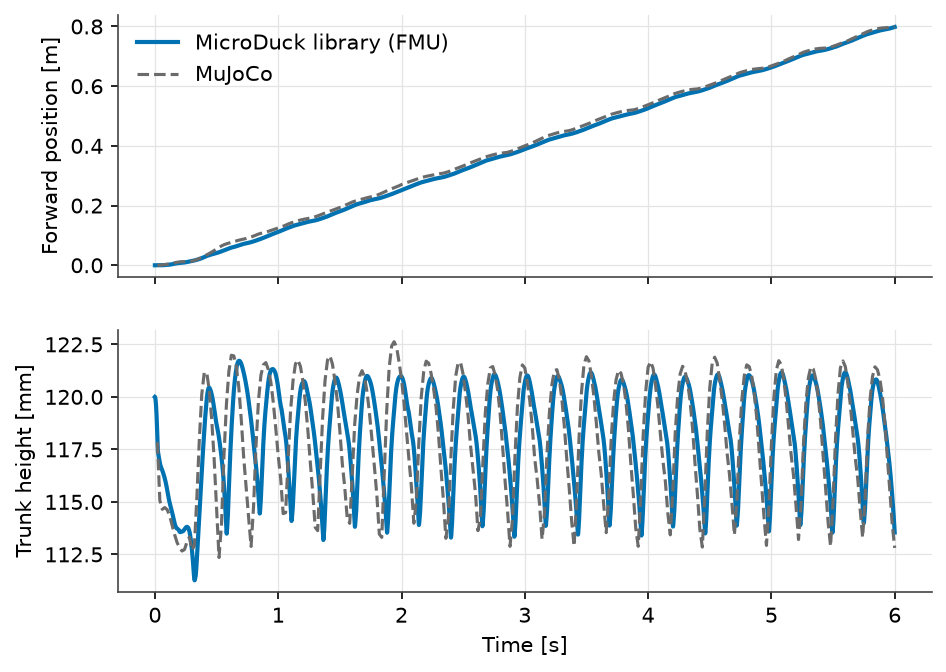

In [4]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(7, 5), sharex=True)
a1.plot(duck["time"], duck["distance"], color=BLUE, label="MicroDuck library (FMU)")
a1.plot(mj["time"], mj["distance"], color=GREY, ls="--", lw=1.5, label="MuJoCo")
a2.plot(duck["time"], 1e3 * duck["trunkHeight"], color=BLUE)
a2.plot(mj["time"], 1e3 * mj["trunkHeight"], color=GREY, ls="--", lw=1.5)
a1.set_ylabel("Forward position [m]"); a1.legend(loc="upper left")
a2.set_ylabel("Trunk height [mm]"); a2.set_xlabel("Time [s]")
plt.show()

## What the plant answers next

### 1. Soft servos used as torque commands

At the walking gain register of 200 (`0.589 N·m/rad` at 7.4 V), the policy swings its angle targets 24° RMS ahead of the knees while staying under 30% of the 1.01 N·m stall torque.

In [5]:
late = (duck["time"] >= 2).to_numpy()
q, q_ref, tau = cols(duck, "q"), cols(duck, "qRef"), cols(duck, "servoTorque")
err = np.degrees(q_ref - q)[late]
print(f"left knee tracking error: {np.sqrt((err[:, 3] ** 2).mean()):.1f} deg RMS")
print(f"right knee tracking error: {np.sqrt((err[:, 12] ** 2).mean()):.1f} deg RMS")
print(f"peak servo torque: {np.abs(tau[late]).max():.2f} N.m (26% of 1.01 N.m stall at 7.4 V)")

left knee tracking error: 23.8 deg RMS
right knee tracking error: 22.4 deg RMS
peak servo torque: 0.26 N.m (26% of 1.01 N.m stall at 7.4 V)


### 2. Supply voltage and a weak knee

Lowering the pack supply to 6.5 V lowers servo power. Feeding the left knee 3.7 V instead of 7.4 V (`walk_fmu(kneeSupply=3.7)`) slows the walk and raises the left knee's tracking error, but in this run it moves almost no copper heating ($R i^2$) onto the right knee.

In [6]:
low = walk_fmu(supply=6.5)
weak = walk_fmu(kneeSupply=3.7)
cu_nom = (RESISTANCE * cols(duck, "motorCurrent")[duck["time"] >= 2] ** 2).mean(0)
cu_weak = (RESISTANCE * cols(weak, "motorCurrent")[weak["time"] >= 2] ** 2).mean(0)
print(f"6.5 V supply: {speed(low):.3f} m/s, mean servo power {6.5 * low['batteryCurrent'][low['time'] >= 2].mean():.2f} W")
print(f"right knee copper loss: {cu_nom[12]:.2f} W healthy -> {cu_weak[12]:.2f} W with left knee at 3.7 V (+{(cu_weak[12] / cu_nom[12] - 1) * 100:.0f}%)")

6.5 V supply: 0.129 m/s, mean servo power 2.02 W
right knee copper loss: 0.41 W healthy -> 0.41 W with left knee at 3.7 V (+0%)
